Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: 10830 | Test: 2708
Loaded 7 optimized models: ['XGBoost', 'Random Forest', 'Gradient Boosting', 'MLP', 'AdaBoost', 'Decision Tree', 'Logistic Regression']
XGBoost                threshold=0.3961  (OOF: P=0.589 R=0.778 F1=0.670)
Random Forest          threshold=0.4413  (OOF: P=0.594 R=0.797 F1=0.681)
Gradient Boosting      threshold=0.3706  (OOF: P=0.557 R=0.802 F1=0.657)
MLP                    threshold=0.2383  (OOF: P=0.497 R=0.799 F1=0.613)
AdaBoost               threshold=0.4437  (OOF: P=0.488 R=0.833 F1=0.616)
Decision Tree          threshold=0.1333  (OOF: P=0.475 R=0.856 F1=0.611)
Logistic Regression    threshold=0.4115  (OOF: P=0.444 R=0.825 F1=0.577)
Final model (Protocol A): Random Forest   |   Runner-up: XGBoost


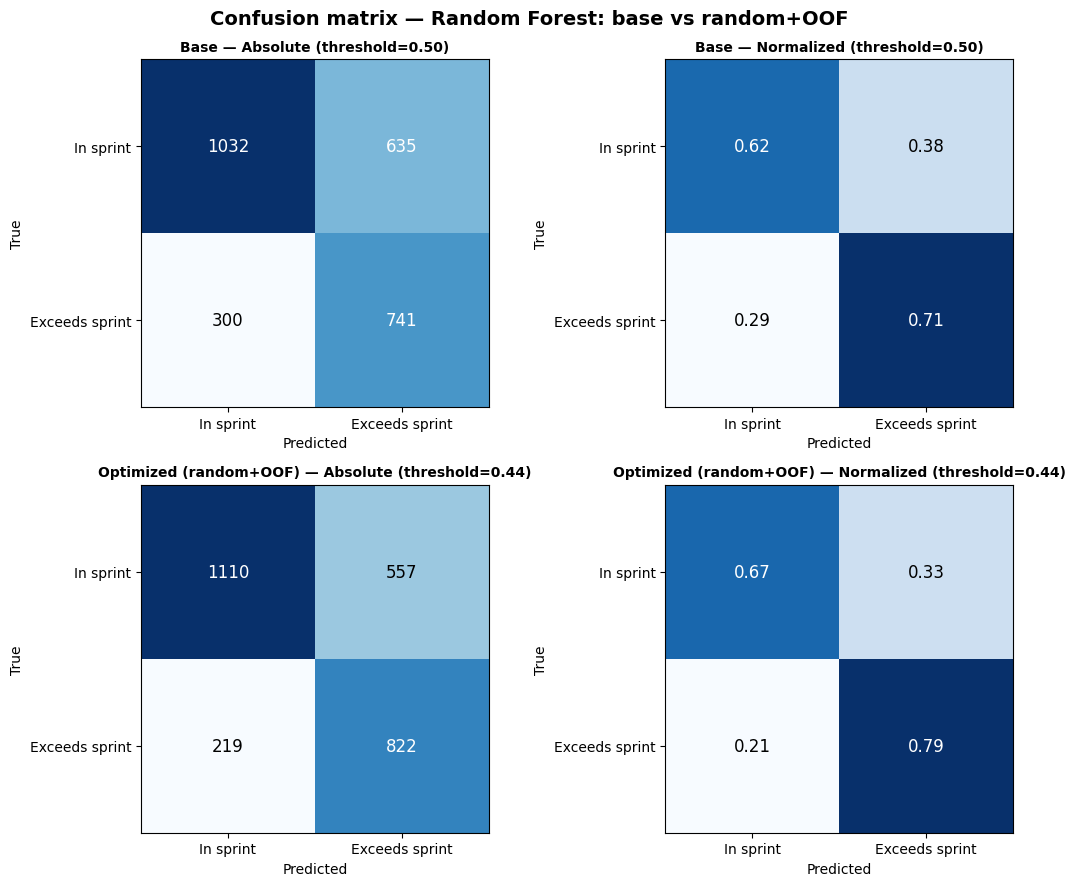

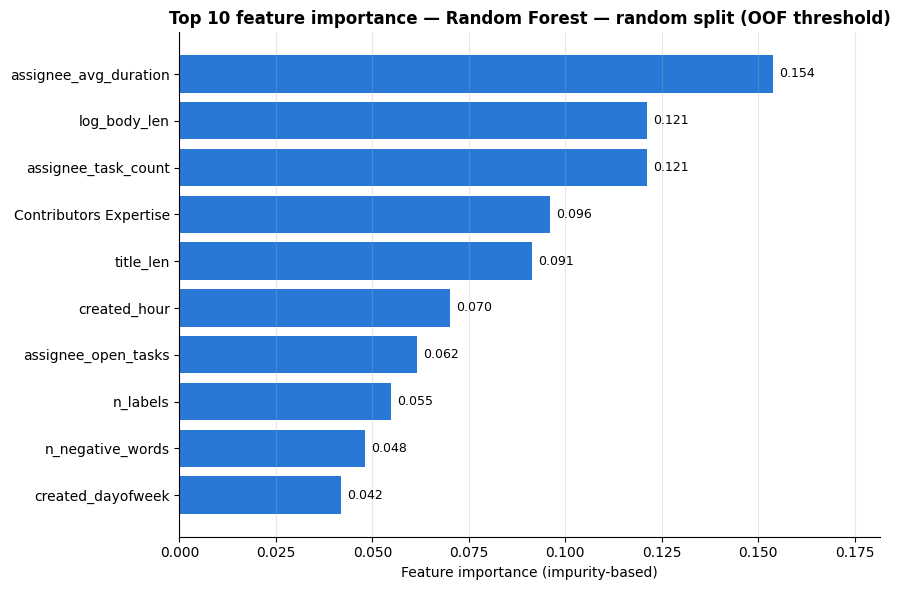

In [2]:
# Protocol B
# Random split with OOF Threshold

from google.colab import drive
drive.mount('/content/drive')

import os, time, warnings
import numpy as np
import pandas as pd
import joblib

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

PROJECT = '/content/drive/MyDrive/ages-sprint-overrun/pipeline'
IN1 = f'{PROJECT}/01_data_prep'
IN2 = f'{PROJECT}/02_random_benchmark'
OUT = f'{PROJECT}/03c_random_oof_threshold'
os.makedirs(OUT, exist_ok=True)

FEATURE_COLS = joblib.load(f'{IN1}/feature_cols.pkl')
X_train, X_test, y_train, y_test = joblib.load(f'{IN2}/split_random.pkl')
cv_skf = joblib.load(f'{IN2}/cv_scheme.pkl')

print(f'Train: {len(X_train)} | Test: {len(X_test)}')

# Reuse optimized models from permissive protocol (A)

modele_opt = joblib.load(f'{PROJECT}/03_random_optimization/modele_optimizate.pkl')
print(f'Loaded {len(modele_opt)} optimized models: {list(modele_opt.keys())}')

# Threshold selection — OOF on train, applied to the random split

from sklearn.metrics import precision_recall_curve, matthews_corrcoef
from sklearn.base import clone

def oof_proba(model, X, y, cv):
    proba = np.full(len(y), np.nan)
    for tr, va in cv.split(X, y):
        m = clone(model)
        m.fit(X.iloc[tr], y.iloc[tr])
        proba[va] = m.predict_proba(X.iloc[va])[:, 1]
    return proba

def prag_optim(model, X, y, cv, nume=''):
    proba = oof_proba(model, X, y, cv)
    ok = ~np.isnan(proba)
    p, r, thr = precision_recall_curve(y[ok], proba[ok])
    f1 = 2 * (p[:-1] * r[:-1]) / (p[:-1] + r[:-1] + 1e-10)
    i = int(np.argmax(f1))
    print(f'{nume:22s} threshold={thr[i]:.4f}  (OOF: P={p[i]:.3f} R={r[i]:.3f} F1={f1[i]:.3f})')
    return float(thr[i])

thresholds = {}
for nume, model in modele_opt.items():
    thresholds[nume] = prag_optim(model, X_train, y_train, cv_skf, nume)

joblib.dump(thresholds, f'{OUT}/thresholds.pkl')

# Final evaluation - test dataset

from sklearn.metrics import (roc_auc_score, f1_score, accuracy_score,
                             precision_score, recall_score)

rows = []
predictii_finale = {}

for nume, model in modele_opt.items():
    thr = thresholds[nume]
    proba = model.predict_proba(X_test)[:, 1]
    pred  = (proba >= thr).astype(int)
    predictii_finale[nume] = {'y_proba': proba, 'y_pred': pred, 'threshold': thr}

    rows.append({
        'Model': nume,
        'Threshold': round(thr, 3),
        'Test AUC': round(roc_auc_score(y_test, proba), 3),
        'Precision (Exceeds)': round(precision_score(y_test, pred, pos_label=1, zero_division=0), 3),
        'Recall (Exceeds)': round(recall_score(y_test, pred, pos_label=1), 3),
        'F1 (Exceeds)': round(f1_score(y_test, pred, pos_label=1), 3),
        'MCC': round(matthews_corrcoef(y_test, pred), 3),
        'Accuracy (weighted)': round(accuracy_score(y_test, pred), 3),
        'F1 (weighted)': round(f1_score(y_test, pred, average='weighted'), 3),
    })

df_final = pd.DataFrame(rows).sort_values('MCC', ascending=False).reset_index(drop=True)
df_final.to_csv(f'{OUT}/table_final_test_results.csv', index=False)
joblib.dump(predictii_finale, f'{OUT}/predictii_finale.pkl')


# MODEL_FINAL - determined here from the results

MODEL_FINAL_OOF = df_final.loc[0, 'Model']
RUNNER_UP_OOF   = df_final.loc[1, 'Model']
joblib.dump(MODEL_FINAL_OOF, f'{OUT}/model_final_name.pkl')
joblib.dump(RUNNER_UP_OOF, f'{OUT}/runner_up_name.pkl')

print(f'Final model (Protocol A): {MODEL_FINAL_OOF}   |   Runner-up: {RUNNER_UP_OOF}')
df_final


# Confusion matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

rezultate_base = joblib.load(f'{PROJECT}/02_random_benchmark/rezultate_base.pkl')
y_pred_base = rezultate_base[MODEL_FINAL_OOF]['y_pred']

thr_oof = thresholds[MODEL_FINAL_OOF]
proba_oof = modele_opt[MODEL_FINAL_OOF].predict_proba(X_test)[:, 1]
y_pred_oof = (proba_oof >= thr_oof).astype(int)

labels = ['In sprint', 'Exceeds sprint']
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
fig.suptitle(f'Confusion matrix — {MODEL_FINAL_OOF}: base vs random+OOF', fontsize=14, fontweight='bold')

configs = [(y_pred_base, 'threshold=0.50', 'Base'),
           (y_pred_oof, f'threshold={thr_oof:.2f}', 'Optimized (random+OOF)')]

for r, (pred, thr_lbl, lbl) in enumerate(configs):
    cm  = confusion_matrix(y_test, pred)
    cmn = confusion_matrix(y_test, pred, normalize='true')
    for col, (mat, fmt, tip) in enumerate([(cm, 'd', 'Absolute'), (cmn, '.2f', 'Normalized')]):
        ax = axes[r, col]
        ax.imshow(mat, cmap='Blues')
        for i in range(2):
            for j in range(2):
                v = mat[i, j]
                ax.text(j, i, format(v, fmt), ha='center', va='center',
                        color='white' if v > mat.max()*0.6 else 'black', fontsize=12)
        ax.set_xticks([0,1]); ax.set_xticklabels(labels)
        ax.set_yticks([0,1]); ax.set_yticklabels(labels)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(f'{lbl} — {tip} ({thr_lbl})', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{OUT}/fig_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

clf = modele_opt[MODEL_FINAL_OOF].named_steps['clf']

if hasattr(clf, 'feature_importances_'):
    imp_oof = pd.Series(clf.feature_importances_, index=FEATURE_COLS)
    xlabel = 'Feature importance (impurity-based)'
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(modele_opt[MODEL_FINAL_OOF], X_test, y_test, n_repeats=10,
                                random_state=RANDOM_STATE, scoring='roc_auc', n_jobs=-1)
    imp_oof = pd.Series(pi.importances_mean, index=FEATURE_COLS)
    xlabel = 'Permutation importance (ROC-AUC drop)'

imp_oof = imp_oof.sort_values(ascending=False)
imp_oof.to_csv(f'{OUT}/table_feature_importance.csv')

top10_oof = imp_oof.head(10).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top10_oof.index, top10_oof.values, color='#2a78d6')
for b, v in zip(bars, top10_oof.values):
    ax.text(b.get_width() + top10_oof.max()*0.01, b.get_y()+b.get_height()/2, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlabel(xlabel)
ax.set_title(f'Top 10 feature importance — {MODEL_FINAL_OOF} — random split (OOF threshold)', fontweight='bold', fontsize=12)
ax.set_xlim(0, top10_oof.max()*1.18)
ax.grid(axis='x', alpha=0.3); ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{OUT}/fig_feature_importance_top10.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import sklearn, xgboost, imblearn, scipy, statsmodels, matplotlib, pandas, numpy
import sys

print(f'Python: {sys.version.split()[0]}')
for lib in [pandas, numpy, sklearn, xgboost, imblearn, scipy, statsmodels, matplotlib]:
    print(f'{lib.__name__}=={lib.__version__}')

Python: 3.13.15
pandas==2.2.3
numpy==2.1.3
sklearn==1.6.1
xgboost==3.4.1
imblearn==0.14.2
scipy==1.16.3
statsmodels==0.15.0
matplotlib==3.10.0
